# Assignment 2 – Pest Image Classification
## Comparative Deep Learning Model Evaluation, Optimization and XAI

**Dataset:** [Pest Dataset (Kaggle – simranvolunesia/pest-dataset)](https://www.kaggle.com/datasets/simranvolunesia/pest-dataset)

**Pipeline:** data loading → EDA → 70/15/15 split → compare 3 pretrained CNNs (ResNet50, MobileNetV2, EfficientNetB0) → pick best → 3 optimisations (data augmentation, LR scheduling, fine-tuning) → final evaluation → XAI (Grad-CAM + Integrated Gradients).

> Run on a **GPU runtime** (Runtime → Change runtime type → T4 GPU). Every number and plot in this notebook is computed when you run it – nothing is hard-coded.

## 1. Setup

In [11]:
import os, gc, glob, random, shutil, time, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

print("TensorFlow version:", tf.__version__)
gpus = tf.config.list_physical_devices("GPU")
print("GPU available:", gpus if gpus else "NO -> Runtime > Change runtime type > GPU")

TensorFlow version: 2.21.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Get the dataset from Kaggle

In [12]:
%pip install -q kagglehub

In [13]:
DATASET_SLUG = "simranvolunesia/pest-dataset"
DATA_ROOT = None

try:
    import kagglehub
    DATA_ROOT = kagglehub.dataset_download(DATASET_SLUG)
    print("Downloaded with kagglehub to:", DATA_ROOT)
except Exception as e:
    print("kagglehub download failed:", e)
    # Fallback: download the zip manually from Kaggle, upload it to /content, re-run this cell
    zips = glob.glob("/content/*.zip")
    if not zips:
        raise RuntimeError("Upload the dataset .zip to /content (left sidebar > Files) and re-run this cell.")
    DATA_ROOT = "/content/pest_dataset_raw"
    os.makedirs(DATA_ROOT, exist_ok=True)
    with zipfile.ZipFile(zips[0]) as z:
        z.extractall(DATA_ROOT)
    print("Extracted", zips[0], "to", DATA_ROOT)

Using Colab cache for faster access to the 'pest-dataset' dataset.
Downloaded with kagglehub to: /kaggle/input/pest-dataset


## About the dataset

| Item | Details |
|---|---|
| Name | Pest Dataset (Kaggle, user *simranvolunesia*) |
| Task | Multi-class image classification of agricultural pests |
| Categories | **9 pest classes** (as stated on the Kaggle dataset page: "9 pests that badly affect agricultural farms") |
| Total images | Counted automatically in the next section (printed in the *Dataset overview* table) |
| Split used | 70 % train / 15 % validation / 15 % test, stratified per class, seed 42 |
| Input size | All images resized to 224 x 224 x 3 |

## 3. Explore the dataset structure

In [14]:
import os

IMG_EXT = (".jpg", ".jpeg", ".png", ".bmp", ".gif")

def show_tree(root, max_depth=3):
    if root is None or not os.path.exists(root):
        print("DATA_ROOT is not yet defined or download has not been run. Please run the Kaggle download cell first.")
        return
    for cur, dirs, files in os.walk(root):
        depth = cur[len(root):].count(os.sep)
        if depth > max_depth:
            dirs[:] = []
            continue
        dirs.sort()
        n_img = sum(f.lower().endswith(IMG_EXT) for f in files)
        print("  " * depth + os.path.basename(cur) + "/" + (f"   [{n_img} images]" if n_img else ""))

try:
    show_tree(DATA_ROOT)
except NameError:
    print("NameError: 'DATA_ROOT' is not defined. Please run the cell in Section 2 (Get the dataset from Kaggle) first to download the dataset.")

pest-dataset/
  pest/
    test/
      aphids/   [50 images]
      armyworm/   [50 images]
      beetle/   [50 images]
      bollworm/   [50 images]
      grasshopper/   [50 images]
      mites/   [50 images]
      mosquito/   [50 images]
      sawfly/   [50 images]
      stem_borer/   [50 images]
    train/
      aphids/   [300 images]
      armyworm/   [300 images]
      beetle/   [300 images]
      bollworm/   [300 images]
      grasshopper/   [300 images]
      mites/   [300 images]
      mosquito/   [300 images]
      sawfly/   [300 images]
      stem_borer/   [300 images]


In [15]:
# The loader below works whether the dataset is a single folder-per-class tree
# or is already divided into train/val/test folders: images of the same class are pooled
# and then re-split 70/15/15 with a fixed seed, exactly like the original assignment.
SPLIT_NAMES = {"train", "training", "val", "valid", "validation", "test", "testing"}

class_files = {}
for root, dirs, files in os.walk(DATA_ROOT):
    imgs = [f for f in files if f.lower().endswith(IMG_EXT)]
    if not imgs:
        continue
    cls = os.path.basename(root).strip().lower()
    if cls in SPLIT_NAMES:          # images directly inside train/val/test have no class label
        continue
    class_files.setdefault(cls, []).extend(os.path.join(root, f) for f in imgs)

classes = sorted(class_files)
if len(classes) < 2:
    raise RuntimeError("Could not find >=2 class folders. Check the tree printed above.")

print("Number of classes:", len(classes))
print("\nImages in each class:")
for c in classes:
    print(f"  {c}: {len(class_files[c])}")
print("\nTotal images:", sum(len(v) for v in class_files.values()))

Number of classes: 9

Images in each class:
  aphids: 350
  armyworm: 350
  beetle: 350
  bollworm: 350
  grasshopper: 350
  mites: 350
  mosquito: 350
  sawfly: 350
  stem_borer: 350

Total images: 3150


DATASET OVERVIEW
  Number of categories : 9
  Total images         : 3150
  Images per class     : min 350, max 350, mean 350


,Images,Share (%)
Class,,
aphids,350,11.11
armyworm,350,11.11
beetle,350,11.11
bollworm,350,11.11
grasshopper,350,11.11
mites,350,11.11
mosquito,350,11.11
sawfly,350,11.11
stem_borer,350,11.11


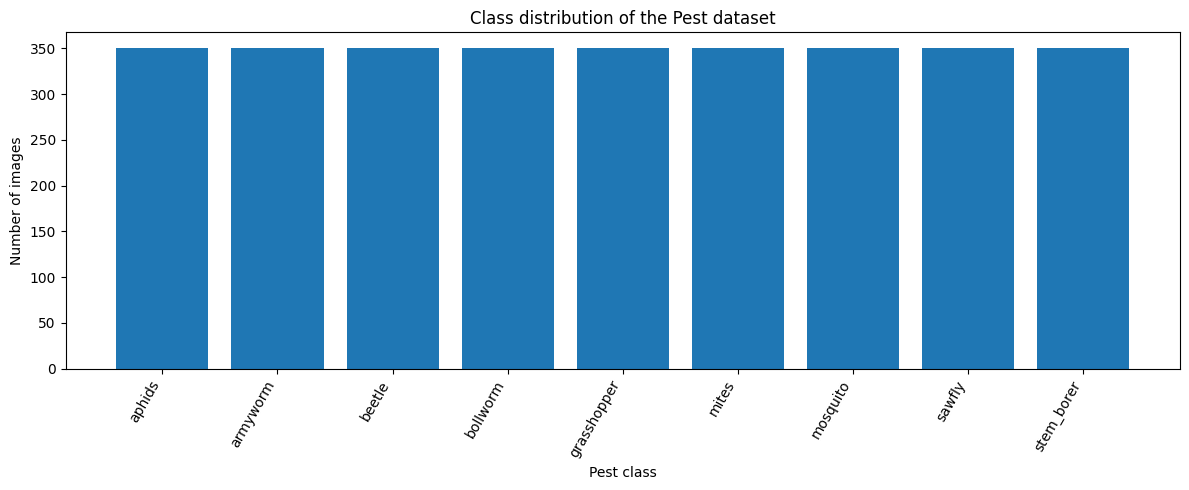

Largest class: aphids (350)  |  Smallest class: aphids (350)
Imbalance ratio (max/min): 1.00


In [16]:
counts = pd.Series({c: len(class_files[c]) for c in classes})

overview = pd.DataFrame({"Images": counts, "Share (%)": (counts / counts.sum() * 100).round(2)})
overview.index.name = "Class"
print("DATASET OVERVIEW")
print(f"  Number of categories : {len(classes)}")
print(f"  Total images         : {counts.sum()}")
print(f"  Images per class     : min {counts.min()}, max {counts.max()}, mean {counts.mean():.0f}")
display(overview)
if len(classes) != 9:
    print(f"NOTE: Kaggle page says 9 pests but {len(classes)} class folders were found - check the tree above.")

plt.figure(figsize=(12, 5))
plt.bar(counts.index, counts.values)
plt.xticks(rotation=60, ha="right")
plt.xlabel("Pest class"); plt.ylabel("Number of images")
plt.title("Class distribution of the Pest dataset")
plt.tight_layout(); plt.show()

print(f"Largest class: {counts.idxmax()} ({counts.max()})  |  Smallest class: {counts.idxmin()} ({counts.min()})")
print(f"Imbalance ratio (max/min): {counts.max() / counts.min():.2f}")

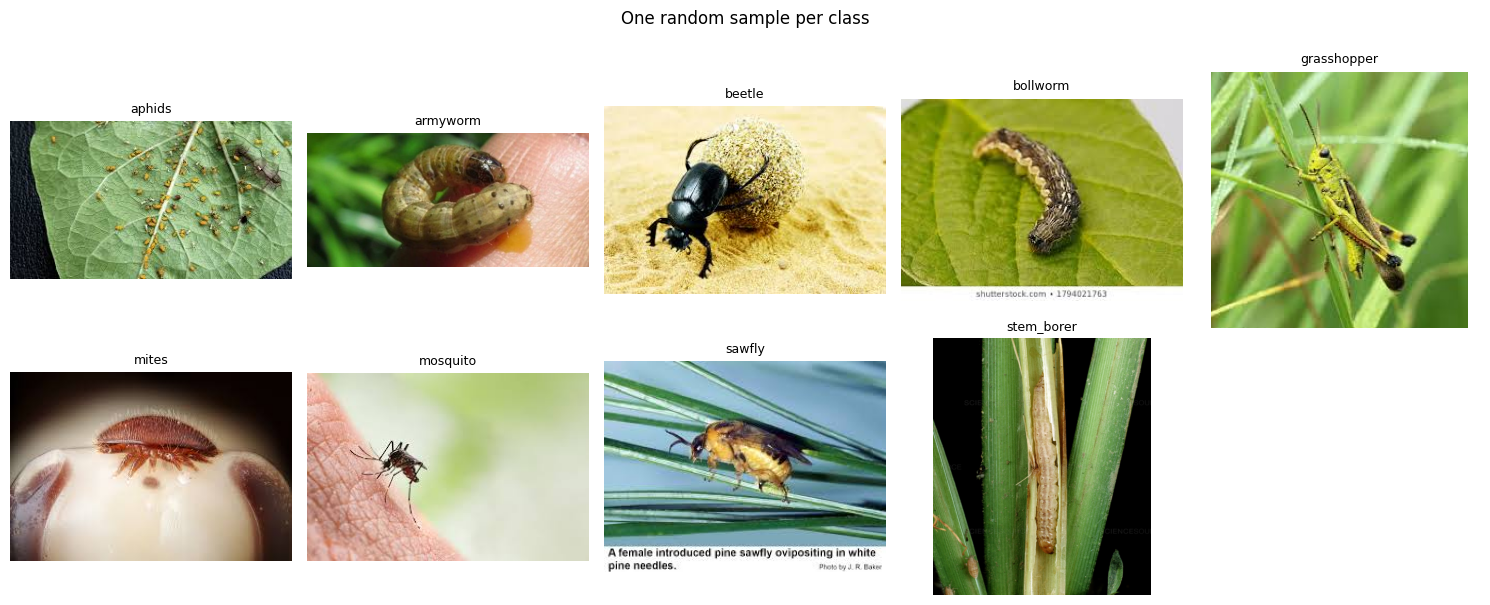

In [17]:
from PIL import Image

ncols = 5
nrows = int(np.ceil(len(classes) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(3 * ncols, 3 * nrows))
axes = np.array(axes).ravel()
for ax in axes:
    ax.axis("off")

rng_vis = random.Random(SEED)
for ax, c in zip(axes, classes):
    with Image.open(rng_vis.choice(class_files[c])) as im:
        ax.imshow(im.convert("RGB"))
    ax.set_title(c, fontsize=9)

plt.suptitle("One random sample per class", y=1.0)
plt.tight_layout(); plt.show()

## 4. Train / validation / test split (70 / 15 / 15, stratified per class)

In [18]:
SPLIT_DIR = "/content/pest_split"
if os.path.exists(SPLIT_DIR):
    shutil.rmtree(SPLIT_DIR)

corrupt = []
for c in classes:
    valid = []
    for p in class_files[c]:
        try:
            with Image.open(p) as im:
                im.verify()
            valid.append(p)
        except Exception:
            corrupt.append(p)

    valid.sort()
    random.Random(SEED).shuffle(valid)

    n = len(valid)
    train_end = int(0.70 * n)
    val_end = int(0.85 * n)
    parts = {"train": valid[:train_end], "val": valid[train_end:val_end], "test": valid[val_end:]}

    for split, paths in parts.items():
        out_dir = os.path.join(SPLIT_DIR, split, c)
        os.makedirs(out_dir, exist_ok=True)
        for i, p in enumerate(paths):
            shutil.copy2(p, os.path.join(out_dir, f"{i:05d}_{os.path.basename(p)}"))

print("Corrupt / unreadable images skipped:", len(corrupt))
for split in ["train", "val", "test"]:
    total = sum(len(os.listdir(os.path.join(SPLIT_DIR, split, c))) for c in classes)
    print(f"{split:5s}: {total}")

Corrupt / unreadable images skipped: 0
train: 2196
val  : 477
test : 477


## 5. Data pipeline

In [19]:
train_dir = os.path.join(SPLIT_DIR, "train")
val_dir   = os.path.join(SPLIT_DIR, "val")
test_dir  = os.path.join(SPLIT_DIR, "test")

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
EPOCHS = 5

train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir, image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    label_mode="int", shuffle=True, seed=SEED)
val_ds = tf.keras.utils.image_dataset_from_directory(
    val_dir, image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    label_mode="int", shuffle=False)
test_ds = tf.keras.utils.image_dataset_from_directory(
    test_dir, image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    label_mode="int", shuffle=False)

class_names = train_ds.class_names
NUM_CLASSES = len(class_names)

# Keep file paths / labels before .prefetch() (used later for metrics and XAI)
val_paths, test_paths = val_ds.file_paths, test_ds.file_paths
def labels_from_paths(paths):
    return np.array([class_names.index(os.path.basename(os.path.dirname(p))) for p in paths])
y_val, y_test = labels_from_paths(val_paths), labels_from_paths(test_paths)

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(AUTOTUNE)
val_ds   = val_ds.prefetch(AUTOTUNE)
test_ds  = test_ds.prefetch(AUTOTUNE)

print("\nClasses:", class_names)
print("NUM_CLASSES:", NUM_CLASSES)

Found 2196 files belonging to 9 classes.
Found 477 files belonging to 9 classes.
Found 477 files belonging to 9 classes.

Classes: ['aphids', 'armyworm', 'beetle', 'bollworm', 'grasshopper', 'mites', 'mosquito', 'sawfly', 'stem_borer']
NUM_CLASSES: 9


## 6. Model zoo

Each ImageNet backbone expects its **own input preprocessing**. The preprocessing is built into the model (small custom layer) so every architecture gets a fair comparison.

In [20]:
from tensorflow.keras.applications import ResNet50, MobileNetV2, EfficientNetB0
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report
)

MODEL_ZOO = {
    "ResNet50": ResNet50,
    "MobileNetV2": MobileNetV2,
    "EfficientNetB0": EfficientNetB0,
}
# EfficientNet already rescales internally ("none"); the others need their own mode.
PREPROCESS_MODE = {"ResNet50": "caffe", "MobileNetV2": "tf", "EfficientNetB0": "none"}

@tf.keras.utils.register_keras_serializable(package="pest")
class ImagenetPreprocess(layers.Layer):
    def __init__(self, mode="tf", **kwargs):
        super().__init__(**kwargs)
        self.mode = mode
    def call(self, x):
        x = tf.cast(x, tf.float32)
        if self.mode == "tf":                       # [-1, 1]
            return x / 127.5 - 1.0
        if self.mode == "torch":                    # /255, ImageNet mean/std
            x = x / 255.0
            return (x - tf.constant([0.485, 0.456, 0.406])) / tf.constant([0.229, 0.224, 0.225])
        if self.mode == "caffe":                    # RGB->BGR, mean subtraction
            return x[..., ::-1] - tf.constant([103.939, 116.779, 123.68])
        return x
    def get_config(self):
        cfg = super().get_config(); cfg.update({"mode": self.mode}); return cfg

data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
], name="data_augmentation")

def build_model(name, augment=False, lr=1e-3, dropout=0.2):
    base = MODEL_ZOO[name](weights="imagenet", include_top=False, input_shape=(224, 224, 3))
    base.trainable = False

    inputs = layers.Input(shape=(224, 224, 3))
    x = data_augmentation(inputs) if augment else inputs
    x = ImagenetPreprocess(PREPROCESS_MODE[name])(x)
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(dropout)(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)

    model = models.Model(inputs, outputs, name=f"{name}_classifier")
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

def evaluate_model(model, ds, y_true):
    t0 = time.time()
    y_prob = model.predict(ds, verbose=0)
    inference_time = time.time() - t0
    y_prob = y_prob / y_prob.sum(axis=1, keepdims=True)
    y_pred = y_prob.argmax(axis=1)
    try:
        auc = roc_auc_score(y_true, y_prob, multi_class="ovr", average="weighted")
    except ValueError:
        auc = np.nan
    metrics = {
        "Accuracy":  accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, average="weighted", zero_division=0),
        "Recall":    recall_score(y_true, y_pred, average="weighted", zero_division=0),
        "F1-score":  f1_score(y_true, y_pred, average="weighted", zero_division=0),
        "Macro-F1":  f1_score(y_true, y_pred, average="macro", zero_division=0),
        "ROC-AUC":   auc,
        "Inference time (s)": inference_time,
    }
    return metrics, y_prob, y_pred

print(len(MODEL_ZOO), "models ready:", list(MODEL_ZOO))

3 models ready: ['ResNet50', 'MobileNetV2', 'EfficientNetB0']


## 7. Compare three pretrained architectures (frozen backbone, same head, same epochs)

In [21]:
results, histories = [], {}
best_val, best_name, best_model, best_time = -1, None, None, None

for name in MODEL_ZOO:
    print("\n" + "=" * 40 + f"\nTraining: {name}\n" + "=" * 40)
    model = build_model(name)

    t0 = time.time()
    hist = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS, verbose=1)
    train_time = time.time() - t0

    val_acc = max(hist.history["val_accuracy"])
    _, test_acc = model.evaluate(test_ds, verbose=0)

    results.append({
        "Model": name,
        "Val Accuracy (%)": round(val_acc * 100, 2),
        "Test Accuracy (%)": round(test_acc * 100, 2),
        "Parameters": model.count_params(),
        "Training Time (sec)": round(train_time, 2),
    })
    histories[name] = hist.history

    if val_acc > best_val:                      # keep only the best model in memory
        best_val, best_name, best_model, best_time = val_acc, name, model, train_time
    else:
        del model
    gc.collect()

results_df = pd.DataFrame(results).sort_values("Val Accuracy (%)", ascending=False).reset_index(drop=True)
print("\nMODEL COMPARISON")
display(results_df)


Training: ResNet50
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Epoch 1/5
69/69 ━━━━━━━━━━━━━━━━━━━━ 34s 295ms/step - accuracy: 0.6416 - loss: 1.1070 - val_accuracy: 0.8889 - val_loss: 0.4512
Epoch 2/5
69/69 ━━━━━━━━━━━━━━━━━━━━ 7s 107ms/step - accuracy: 0.9185 - loss: 0.3119 - val_accuracy: 0.9497 - val_loss: 0.2388
Epoch 3/5
69/69 ━━━━━━━━━━━━━━━━━━━━ 8s 116ms/step - accuracy: 0.9677 - loss: 0.1786 - val_accuracy: 0.9790 - val_loss: 0.1555
Epoch 4/5
69/69 ━━━━━━━━━━━━━━━━━━━━ 10s 112ms/step - accuracy: 0.9832 - loss: 0.1183 - val_accuracy: 0.9853 - val_loss: 0.1057
Epoch 5/5
69/69 ━━━━━━━━━━━━━━━━━━━━ 8s 114ms/step - accuracy: 0.9882 - loss: 0.0910 - val_accuracy: 0.9916 - val_loss: 0.0725

Training: MobileNetV2
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/5
69/69 ━━━━━━━━━━━━━━━━━━━━ 27s 227ms/step - accuracy: 0.5747 - loss: 1.2527 - val_accuracy: 0.8239 - val_loss: 0.6354
Epoch 2/5
69/69 ━━━━━━━━━━━━━━━━━━━━ 3s 49ms/step - accuracy: 0.8474 - loss: 0.5288 - val_ac

,Model,Val Accuracy (%),Test Accuracy (%),Parameters,Training Time (sec)
0,ResNet50,99.16,98.95,23606153,67.41
1,MobileNetV2,98.11,97.69,2269513,44.63
2,EfficientNetB0,95.39,96.86,4061100,108.55


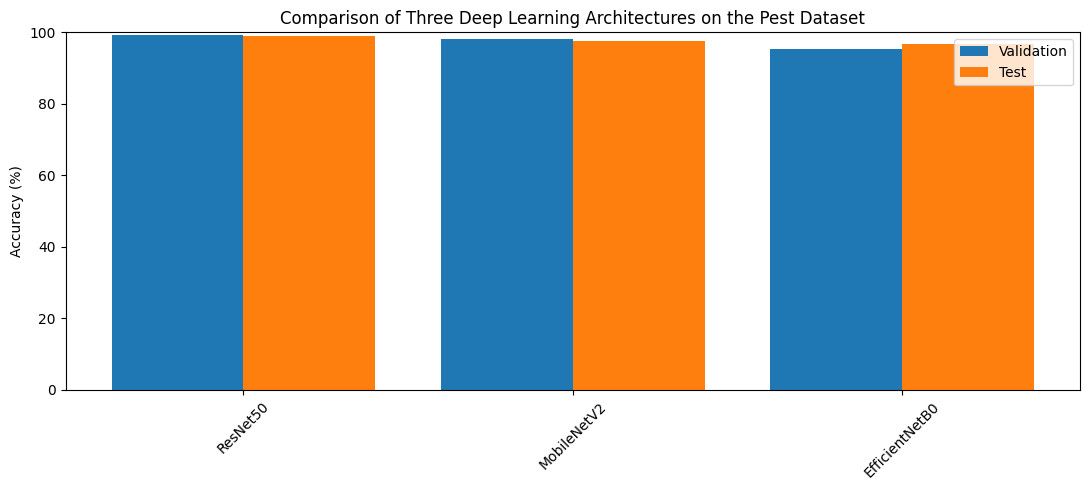

Best model by validation accuracy: ResNet50


In [22]:
x = np.arange(len(results_df)); w = 0.4
plt.figure(figsize=(11, 5))
plt.bar(x - w/2, results_df["Val Accuracy (%)"], w, label="Validation")
plt.bar(x + w/2, results_df["Test Accuracy (%)"], w, label="Test")
plt.xticks(x, results_df["Model"], rotation=45)
plt.ylabel("Accuracy (%)"); plt.ylim(0, 100)
plt.title("Comparison of Three Deep Learning Architectures on the Pest Dataset")
plt.legend(); plt.tight_layout(); plt.show()

results_df.to_csv("/content/three_model_comparison.csv", index=False)
BEST_NAME = best_name           # chosen on VALIDATION accuracy (no test leakage)
print("Best model by validation accuracy:", BEST_NAME)

## 8. Baseline of the best model

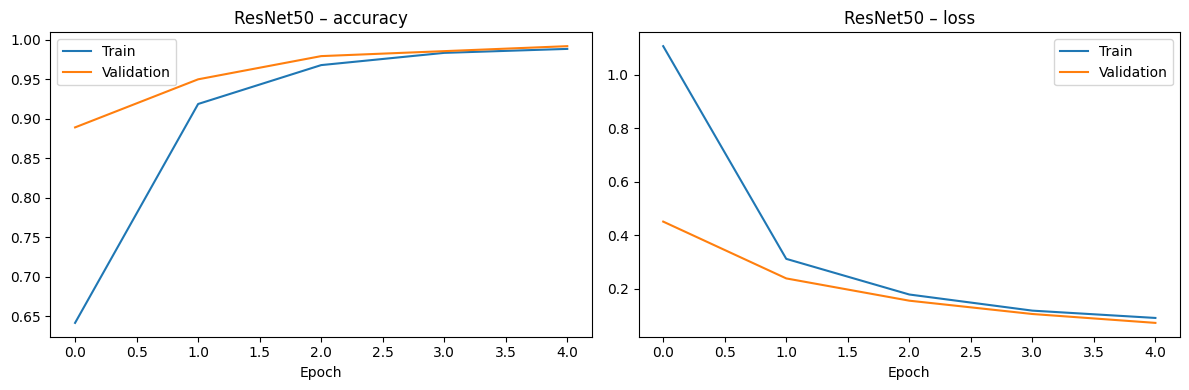

ResNet50 baseline saved. Training time: 67.4s | best val acc: 99.16%


In [23]:
baseline_model, baseline_time = best_model, best_time
baseline_hist = histories[BEST_NAME]
baseline_path = f"/content/{BEST_NAME}_baseline.keras"
baseline_model.save(baseline_path)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(baseline_hist["accuracy"], label="Train"); ax[0].plot(baseline_hist["val_accuracy"], label="Validation")
ax[0].set_title(f"{BEST_NAME} – accuracy"); ax[0].set_xlabel("Epoch"); ax[0].legend()
ax[1].plot(baseline_hist["loss"], label="Train"); ax[1].plot(baseline_hist["val_loss"], label="Validation")
ax[1].set_title(f"{BEST_NAME} – loss"); ax[1].set_xlabel("Epoch"); ax[1].legend()
plt.tight_layout(); plt.show()

print(f"{BEST_NAME} baseline saved. Training time: {baseline_time:.1f}s | "
      f"best val acc: {max(baseline_hist['val_accuracy'])*100:.2f}%")

In [24]:
base_metrics, base_prob, base_pred = evaluate_model(baseline_model, test_ds, y_test)
print(f"{BEST_NAME} baseline – TEST metrics")
for k, v in base_metrics.items():
    print(f"  {k:20s}: {v:.4f}")

variants = {"Baseline": {"model": baseline_model, "val_acc": max(baseline_hist["val_accuracy"]) * 100,
                         "time": baseline_time}}

ResNet50 baseline – TEST metrics
  Accuracy            : 0.9895
  Precision           : 0.9895
  Recall              : 0.9895
  F1-score            : 0.9895
  Macro-F1            : 0.9895
  ROC-AUC             : 0.9998
  Inference time (s)  : 8.9047


## 9. Optimisation techniques

### 9.1 Data augmentation

In [25]:
aug_model = build_model(BEST_NAME, augment=True)
t0 = time.time()
aug_hist = aug_model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS, verbose=1)
aug_time = time.time() - t0

variants["Data Augmentation"] = {"model": aug_model, "val_acc": max(aug_hist.history["val_accuracy"]) * 100, "time": aug_time}
print(f"\nData augmentation – time {aug_time:.1f}s | best val acc {variants['Data Augmentation']['val_acc']:.2f}%")

Epoch 1/5
69/69 ━━━━━━━━━━━━━━━━━━━━ 25s 222ms/step - accuracy: 0.5742 - loss: 1.2441 - val_accuracy: 0.8281 - val_loss: 0.5866
Epoch 2/5
69/69 ━━━━━━━━━━━━━━━━━━━━ 13s 189ms/step - accuracy: 0.8297 - loss: 0.5457 - val_accuracy: 0.8889 - val_loss: 0.4251
Epoch 3/5
69/69 ━━━━━━━━━━━━━━━━━━━━ 14s 204ms/step - accuracy: 0.8857 - loss: 0.3897 - val_accuracy: 0.9182 - val_loss: 0.3109
Epoch 4/5
69/69 ━━━━━━━━━━━━━━━━━━━━ 14s 202ms/step - accuracy: 0.9240 - loss: 0.2772 - val_accuracy: 0.9371 - val_loss: 0.2536
Epoch 5/5
69/69 ━━━━━━━━━━━━━━━━━━━━ 13s 184ms/step - accuracy: 0.9485 - loss: 0.2231 - val_accuracy: 0.9581 - val_loss: 0.2068

Data augmentation – time 78.6s | best val acc 95.81%


### 9.2 Learning-rate scheduling (ReduceLROnPlateau)

In [26]:
from tensorflow.keras.callbacks import ReduceLROnPlateau

lr_model = build_model(BEST_NAME)
reduce_lr = ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=1, min_lr=1e-6, verbose=1)

t0 = time.time()
lr_hist = lr_model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS, callbacks=[reduce_lr], verbose=1)
lr_time = time.time() - t0

variants["LR Scheduling"] = {"model": lr_model, "val_acc": max(lr_hist.history["val_accuracy"]) * 100, "time": lr_time}
print(f"\nLR scheduling – time {lr_time:.1f}s | best val acc {variants['LR Scheduling']['val_acc']:.2f}%")

Epoch 1/5
69/69 ━━━━━━━━━━━━━━━━━━━━ 28s 270ms/step - accuracy: 0.6366 - loss: 1.1128 - val_accuracy: 0.8889 - val_loss: 0.4602 - learning_rate: 0.0010
Epoch 2/5
69/69 ━━━━━━━━━━━━━━━━━━━━ 9s 137ms/step - accuracy: 0.9212 - loss: 0.3210 - val_accuracy: 0.9581 - val_loss: 0.2363 - learning_rate: 0.0010
Epoch 3/5
69/69 ━━━━━━━━━━━━━━━━━━━━ 10s 147ms/step - accuracy: 0.9681 - loss: 0.1770 - val_accuracy: 0.9790 - val_loss: 0.1456 - learning_rate: 0.0010
Epoch 4/5
69/69 ━━━━━━━━━━━━━━━━━━━━ 11s 158ms/step - accuracy: 0.9836 - loss: 0.1168 - val_accuracy: 0.9790 - val_loss: 0.1022 - learning_rate: 0.0010
Epoch 5/5
69/69 ━━━━━━━━━━━━━━━━━━━━ 10s 151ms/step - accuracy: 0.9904 - loss: 0.0811 - val_accuracy: 0.9874 - val_loss: 0.0752 - learning_rate: 0.0010

LR scheduling – time 69.2s | best val acc 98.74%


### 9.3 Fine-tuning the upper layers
Starts from the *trained baseline* (so the new head is already sensible), unfreezes the last 20 backbone layers (BatchNorm layers stay frozen) and trains with a very small learning rate.

In [27]:
ft_model = tf.keras.models.load_model(baseline_path)

def get_base_model(model):
    for l in model.layers:
        if isinstance(l, tf.keras.Model) and not isinstance(l, tf.keras.Sequential):
            return l
    raise ValueError("Backbone not found")

ft_base = get_base_model(ft_model)
ft_base.trainable = True
for l in ft_base.layers[:-20]:
    l.trainable = False
for l in ft_base.layers[-20:]:
    if isinstance(l, layers.BatchNormalization):
        l.trainable = False

ft_model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
                 loss="sparse_categorical_crossentropy", metrics=["accuracy"])
print("Trainable parameters:", int(sum(np.prod(w.shape) for w in ft_model.trainable_weights)))

t0 = time.time()
ft_hist = ft_model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS, verbose=1)
ft_time = time.time() - t0

variants["Fine-Tuning"] = {"model": ft_model, "val_acc": max(ft_hist.history["val_accuracy"]) * 100,
                           "time": baseline_time + ft_time}   # baseline + fine-tuning stage
print(f"\nFine-tuning – stage time {ft_time:.1f}s (total with baseline {baseline_time + ft_time:.1f}s) "
      f"| best val acc {variants['Fine-Tuning']['val_acc']:.2f}%")

Trainable parameters: 8937481
Epoch 1/5
69/69 ━━━━━━━━━━━━━━━━━━━━ 36s 332ms/step - accuracy: 0.9923 - loss: 0.0411 - val_accuracy: 1.0000 - val_loss: 0.0148
Epoch 2/5
69/69 ━━━━━━━━━━━━━━━━━━━━ 11s 164ms/step - accuracy: 0.9991 - loss: 0.0104 - val_accuracy: 1.0000 - val_loss: 0.0045
Epoch 3/5
69/69 ━━━━━━━━━━━━━━━━━━━━ 12s 180ms/step - accuracy: 0.9991 - loss: 0.0058 - val_accuracy: 1.0000 - val_loss: 0.0016
Epoch 4/5
69/69 ━━━━━━━━━━━━━━━━━━━━ 12s 178ms/step - accuracy: 0.9995 - loss: 0.0029 - val_accuracy: 1.0000 - val_loss: 8.9933e-04
Epoch 5/5
69/69 ━━━━━━━━━━━━━━━━━━━━ 11s 161ms/step - accuracy: 0.9995 - loss: 0.0027 - val_accuracy: 1.0000 - val_loss: 9.4561e-04

Fine-tuning – stage time 83.2s (total with baseline 150.6s) | best val acc 100.00%


## 10. Compare baseline vs. optimisations

In [28]:
rows, preds = [], {}
for vname, v in variants.items():
    m, prob, pred = evaluate_model(v["model"], test_ds, y_test)
    preds[vname] = (prob, pred)
    rows.append({
        "Model / Optimization": f"{BEST_NAME} – {vname}",
        "Best Val Accuracy (%)": round(v["val_acc"], 2),
        "Test Accuracy (%)": round(m["Accuracy"] * 100, 2),
        "Precision": round(m["Precision"], 4), "Recall": round(m["Recall"], 4),
        "F1-score": round(m["F1-score"], 4), "ROC-AUC": round(m["ROC-AUC"], 4),
        "Training Time (s)": round(v["time"], 1),
        "Inference Time (s)": round(m["Inference time (s)"], 2),
    })

comparison = pd.DataFrame(rows)
display(comparison)
comparison.to_csv("/content/optimization_comparison.csv", index=False)

,Model / Optimization,Best Val Accuracy (%),Test Accuracy (%),Precision,Recall,F1-score,ROC-AUC,Training Time (s),Inference Time (s)
0,ResNet50 – Baseline,99.16,98.95,0.9895,0.9895,0.9895,0.9998,67.4,1.65
1,ResNet50 – Data Augmentation,95.81,95.60,0.9570,0.9560,0.9559,0.9964,78.6,5.36
2,ResNet50 – LR Scheduling,98.74,98.74,0.9876,0.9874,0.9874,0.9996,69.2,8.68
3,ResNet50 – Fine-Tuning,100.00,99.79,0.9979,0.9979,0.9979,0.9999,150.6,8.63


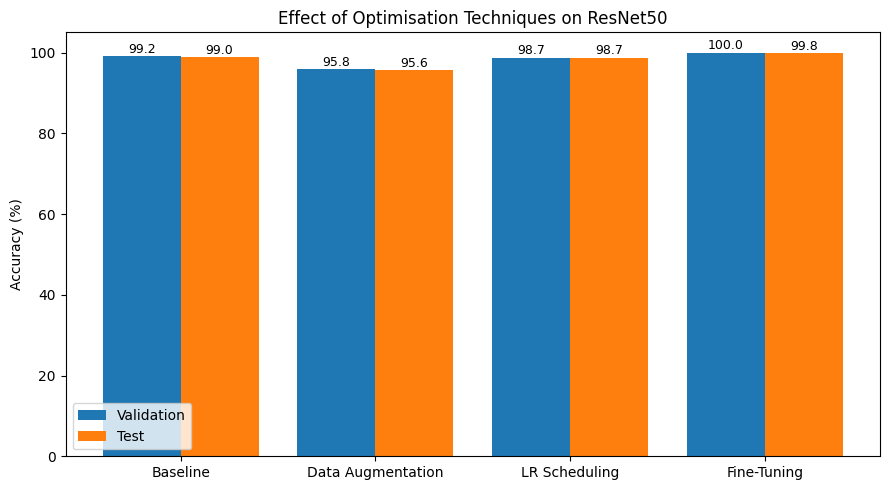

Final model = ResNet50 – Fine-Tuning (selected on validation accuracy, saved).


In [29]:
labels = list(variants)
x = np.arange(len(labels)); w = 0.4
plt.figure(figsize=(9, 5))
b1 = plt.bar(x - w/2, comparison["Best Val Accuracy (%)"], w, label="Validation")
b2 = plt.bar(x + w/2, comparison["Test Accuracy (%)"], w, label="Test")
for bars in (b1, b2):
    for r in bars:
        plt.text(r.get_x() + r.get_width()/2, r.get_height() + 0.8, f"{r.get_height():.1f}", ha="center", fontsize=9)
plt.xticks(x, labels); plt.ylim(0, 105); plt.ylabel("Accuracy (%)")
plt.title(f"Effect of Optimisation Techniques on {BEST_NAME}")
plt.legend(); plt.tight_layout(); plt.show()

FINAL_VARIANT = max(variants, key=lambda k: variants[k]["val_acc"])     # pick on validation
final_model = variants[FINAL_VARIANT]["model"]
y_prob_final, y_pred_final = preds[FINAL_VARIANT]
final_model.save("/content/pest_final_model.keras")
print(f"Final model = {BEST_NAME} – {FINAL_VARIANT} (selected on validation accuracy, saved).")

## 11. Detailed evaluation of the final model

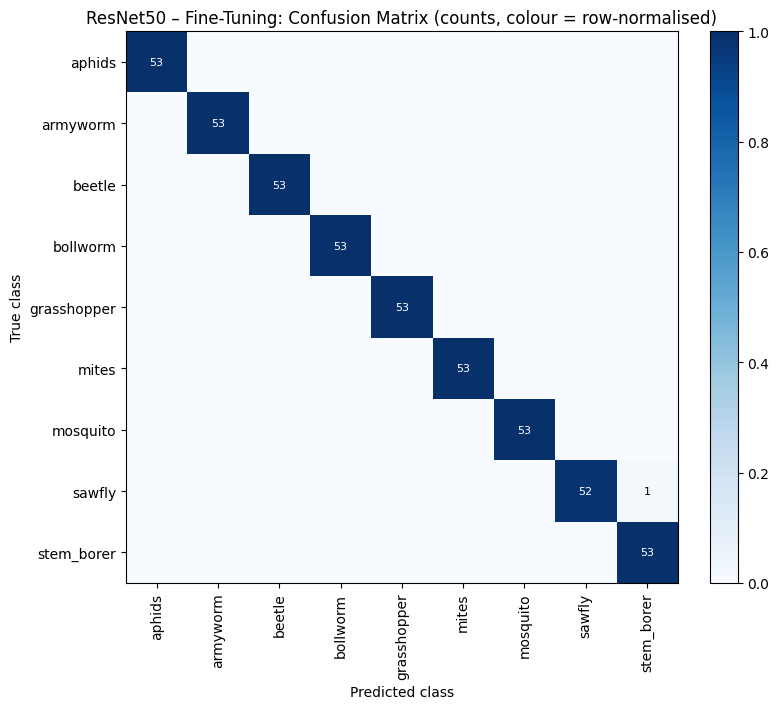

In [30]:
cm = confusion_matrix(y_test, y_pred_final, labels=range(NUM_CLASSES))
cm_norm = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)

fig, ax = plt.subplots(figsize=(max(8, NUM_CLASSES * 0.9), max(7, NUM_CLASSES * 0.8)))
im = ax.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
plt.colorbar(im, fraction=0.046)
ax.set_xticks(range(NUM_CLASSES)); ax.set_xticklabels(class_names, rotation=90)
ax.set_yticks(range(NUM_CLASSES)); ax.set_yticklabels(class_names)
if NUM_CLASSES <= 20:
    for i in range(NUM_CLASSES):
        for j in range(NUM_CLASSES):
            if cm[i, j]:
                ax.text(j, i, cm[i, j], ha="center", va="center",
                        color="white" if cm_norm[i, j] > 0.5 else "black", fontsize=8)
ax.set_xlabel("Predicted class"); ax.set_ylabel("True class")
ax.set_title(f"{BEST_NAME} – {FINAL_VARIANT}: Confusion Matrix (counts, colour = row-normalised)")
plt.tight_layout(); plt.show()

In [31]:
print(f"{BEST_NAME} – {FINAL_VARIANT}: Classification Report\n")
print(classification_report(y_test, y_pred_final, target_names=class_names, digits=4, zero_division=0))

off = cm.copy(); np.fill_diagonal(off, 0)
pairs = sorted(((off[i, j], class_names[i], class_names[j])
                for i in range(NUM_CLASSES) for j in range(NUM_CLASSES) if off[i, j] > 0), reverse=True)[:5]
print("Most frequently confused pairs (true -> predicted):")
for n_err, t, p in pairs:
    print(f"  {t} -> {p}: {n_err} images")
if not pairs:
    print("  No misclassifications on the test set.")

ResNet50 – Fine-Tuning: Classification Report

              precision    recall  f1-score   support

      aphids     1.0000    1.0000    1.0000        53
    armyworm     1.0000    1.0000    1.0000        53
      beetle     1.0000    1.0000    1.0000        53
    bollworm     1.0000    1.0000    1.0000        53
 grasshopper     1.0000    1.0000    1.0000        53
       mites     1.0000    1.0000    1.0000        53
    mosquito     1.0000    1.0000    1.0000        53
      sawfly     1.0000    0.9811    0.9905        53
  stem_borer     0.9815    1.0000    0.9907        53

    accuracy                         0.9979       477
   macro avg     0.9979    0.9979    0.9979       477
weighted avg     0.9979    0.9979    0.9979       477

Most frequently confused pairs (true -> predicted):
  sawfly -> stem_borer: 1 images


## 12. Explainable AI (XAI)

In [32]:
def split_model(model):
    base = get_base_model(model)
    idx = model.layers.index(base)
    pre  = [l for l in model.layers[:idx] if not isinstance(l, layers.InputLayer)]
    post = model.layers[idx + 1:]
    return base, pre, post

def load_img_array(path):
    return tf.keras.utils.img_to_array(tf.keras.utils.load_img(path, target_size=IMG_SIZE))

def grad_cam(model, img, class_idx):
    base, pre, post = split_model(model)
    x = tf.convert_to_tensor(img[None], dtype=tf.float32)
    for l in pre:
        x = l(x)
    with tf.GradientTape() as tape:
        feats = base(x, training=False)          # last convolutional feature map
        tape.watch(feats)
        y = feats
        for l in post:
            y = l(y)
        score = y[:, class_idx]
    grads = tape.gradient(score, feats)
    weights = tf.reduce_mean(grads, axis=(0, 1, 2))
    cam = tf.nn.relu(tf.reduce_sum(feats[0] * weights, axis=-1))
    cam = cam / (tf.reduce_max(cam) + 1e-8)
    return tf.image.resize(cam[..., None], IMG_SIZE)[..., 0].numpy()

def integrated_gradients(model, img, class_idx, steps=50):
    x = tf.convert_to_tensor(img[None], dtype=tf.float32)
    baseline = tf.zeros_like(x)                                   # black image
    alphas = tf.linspace(0.0, 1.0, steps + 1)[:, None, None, None]
    interp = baseline + alphas * (x - baseline)
    with tf.GradientTape() as tape:
        tape.watch(interp)
        scores = model(interp, training=False)[:, class_idx]
    grads = tape.gradient(scores, interp)
    avg = tf.reduce_mean((grads[:-1] + grads[1:]) / 2.0, axis=0)  # trapezoidal rule
    attr = tf.reduce_sum(tf.abs((x[0] - baseline[0]) * avg), axis=-1).numpy()
    attr = np.clip(attr, 0, np.percentile(attr, 99))
    return attr / (attr.max() + 1e-8)

# a few correct and (if any) wrong predictions from different parts of the test set
rng = np.random.default_rng(SEED)
wrong = np.where(y_pred_final != y_test)[0]
right = np.where(y_pred_final == y_test)[0]
chosen = list(rng.choice(wrong, size=min(2, len(wrong)), replace=False)) if len(wrong) else []
chosen += list(rng.choice(right, size=min(4, len(right)), replace=False))
print("Images explained:", len(chosen), "(including", min(2, len(wrong)), "misclassified)")

Images explained: 5 (including 1 misclassified)


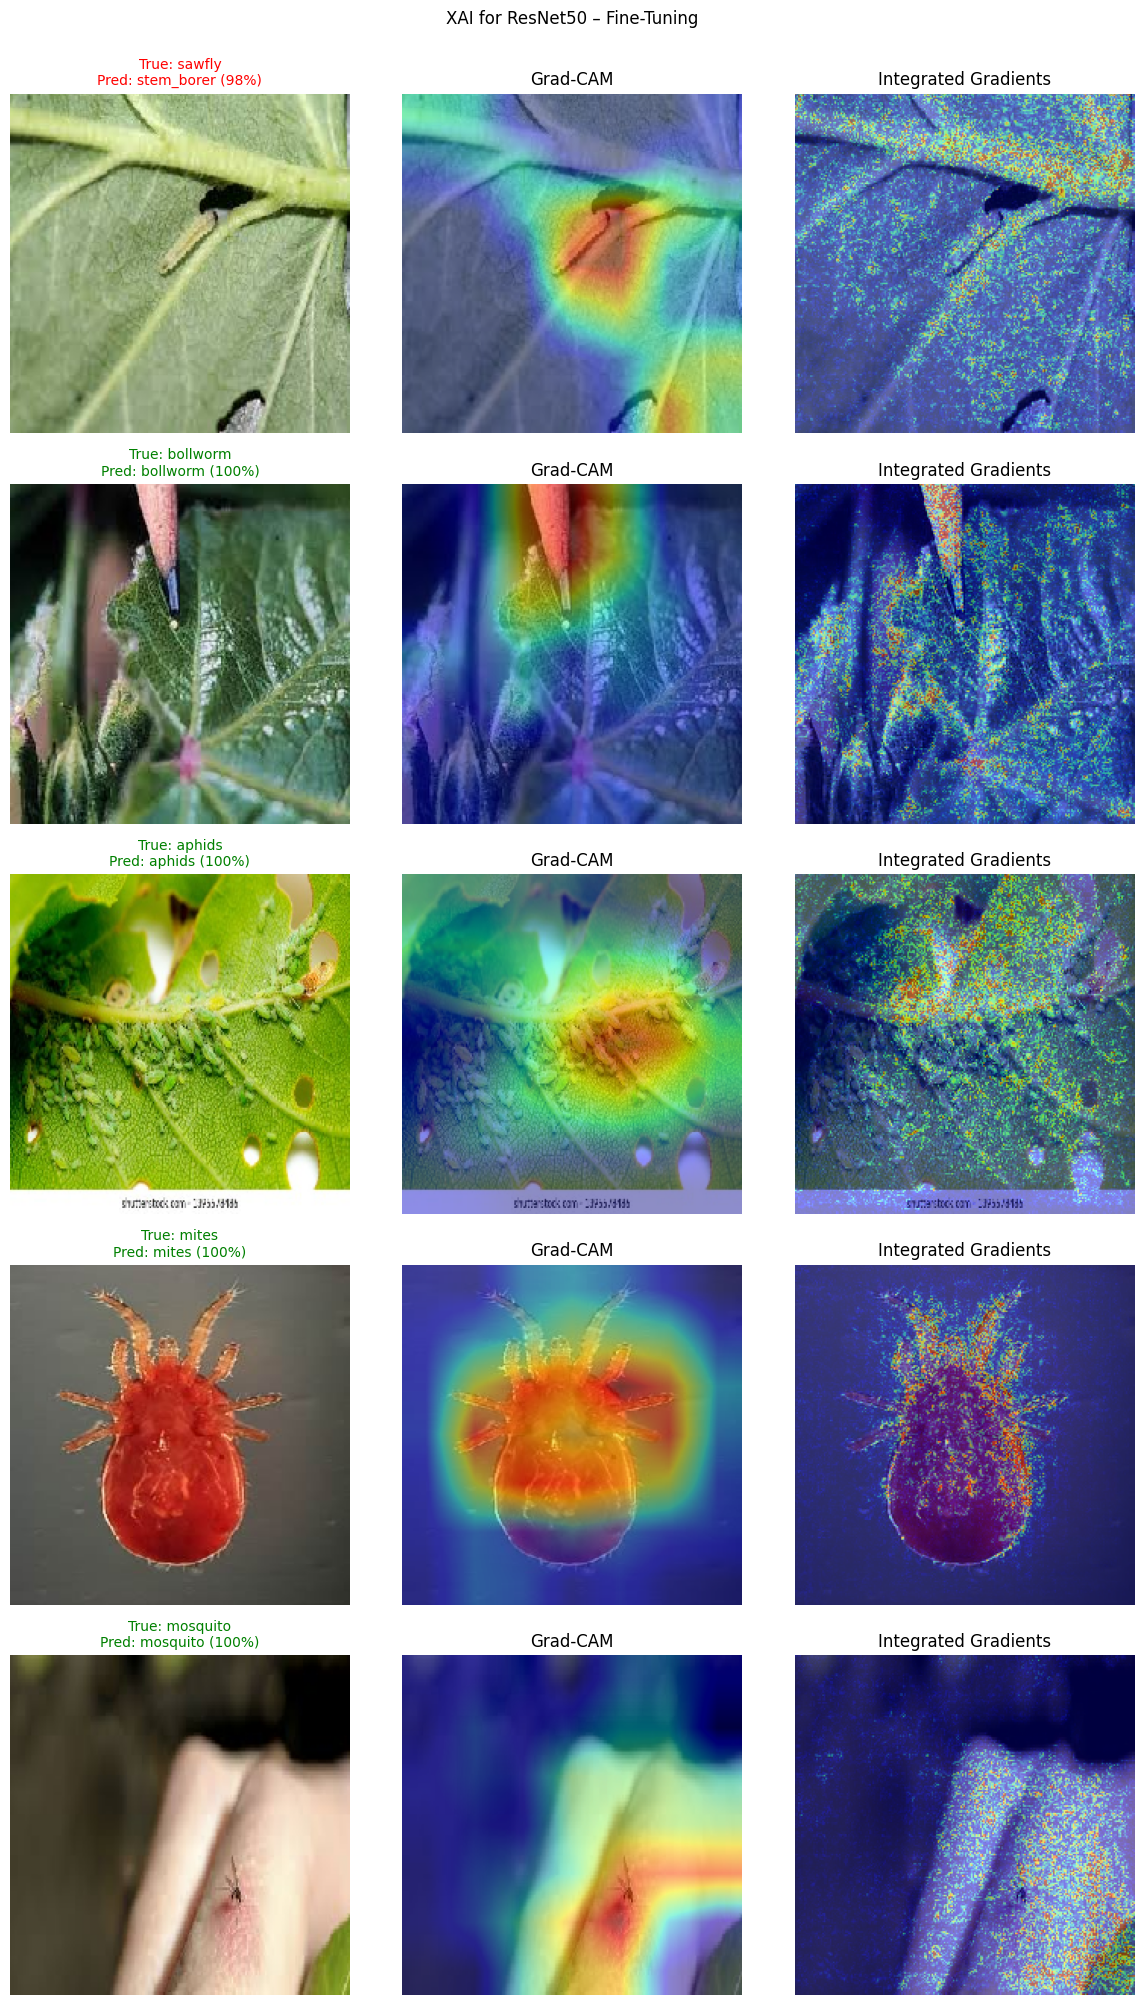

In [33]:
# Grad-CAM and Integrated Gradients, side by side
fig, axes = plt.subplots(len(chosen), 3, figsize=(12, 4 * len(chosen)))
axes = np.atleast_2d(axes)

for row, idx in enumerate(chosen):
    img = load_img_array(test_paths[idx])
    true_c, pred_c = int(y_test[idx]), int(y_pred_final[idx])
    conf = float(y_prob_final[idx, pred_c])

    cam = grad_cam(final_model, img, pred_c)
    ig  = integrated_gradients(final_model, img, pred_c)

    axes[row, 0].imshow(img.astype("uint8"))
    axes[row, 0].set_title(f"True: {class_names[true_c]}\nPred: {class_names[pred_c]} ({conf:.0%})", fontsize=10,
                           color="green" if true_c == pred_c else "red")
    axes[row, 1].imshow(img.astype("uint8")); axes[row, 1].imshow(cam, cmap="jet", alpha=0.45)
    axes[row, 1].set_title("Grad-CAM")
    axes[row, 2].imshow(img.astype("uint8")); axes[row, 2].imshow(ig, cmap="jet", alpha=0.5)
    axes[row, 2].set_title("Integrated Gradients")
    for a in axes[row]:
        a.axis("off")

plt.suptitle(f"XAI for {BEST_NAME} – {FINAL_VARIANT}", y=1.0)
plt.tight_layout(); plt.show()

## 13. Final summary

In [34]:
print("=" * 60)
print("SUMMARY")
print("=" * 60)
print(f"Dataset          : Pest dataset, {NUM_CLASSES} classes")
n_train = sum(len(os.listdir(os.path.join(SPLIT_DIR, 'train', c))) for c in classes)
print(f"Train/Val/Test   : {n_train} / {len(y_val)} / {len(y_test)} images")
print(f"Best architecture: {BEST_NAME} (val acc {results_df.iloc[0]['Val Accuracy (%)']:.2f}%, test acc {results_df.iloc[0]['Test Accuracy (%)']:.2f}%)")
base_test = comparison.loc[0, "Test Accuracy (%)"]
for _, r in comparison.iloc[1:].iterrows():
    print(f"  {r['Model / Optimization'].split(' – ')[1]:18s}: test acc {r['Test Accuracy (%)']:.2f}%  ({r['Test Accuracy (%)'] - base_test:+.2f} vs baseline)")
print(f"Final model      : {BEST_NAME} – {FINAL_VARIANT} -> test acc {accuracy_score(y_test, y_pred_final)*100:.2f}%")
print("\nThree-model table:")
display(results_df)

SUMMARY
Dataset          : Pest dataset, 9 classes
Train/Val/Test   : 2196 / 477 / 477 images
Best architecture: ResNet50 (val acc 99.16%, test acc 98.95%)
  Data Augmentation : test acc 95.60%  (-3.35 vs baseline)
  LR Scheduling     : test acc 98.74%  (-0.21 vs baseline)
  Fine-Tuning       : test acc 99.79%  (+0.84 vs baseline)
Final model      : ResNet50 – Fine-Tuning -> test acc 99.79%

Three-model table:


,Model,Val Accuracy (%),Test Accuracy (%),Parameters,Training Time (sec)
0,ResNet50,99.16,98.95,23606153,67.41
1,MobileNetV2,98.11,97.69,2269513,44.63
2,EfficientNetB0,95.39,96.86,4061100,108.55
